In [8]:
import numpy as np, matplotlib.pyplot as plt, time, ctypes, subprocess, os, shutil
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3})

# ---------------- global parameters ----------------
N      = 12        # particles
L      = 10.0      # box side (2-D square)
mass   = np.ones(N)
k      = 15.0      # spring constant
r0     = 0.8       # spring rest length
r_c    = 2.0       # interaction cut-off
r_s    = 1.5       # taper starts here (force -> 0 smoothly at r_c)
E_WALL = 1.0       # wall restitution coefficient (1 = perfectly elastic)

def initial_state(seed=0, N=N, L=L):
    rng = np.random.default_rng(seed)
    pos = rng.uniform(0, L, size=(N, 2))
    vel = rng.uniform(-1, 1, size=(N, 2))
    return pos, vel

pos0, vel0 = initial_state(0)
print(pos0.shape, vel0.shape, pos0.dtype)

(12, 2) (12, 2) float64


In [9]:
def wall_reflection(pos, vel, L, e=1.0):
    '''Mirror reflection off the 4 walls of the box [0,L]^2 (works on copies).'''
    pos, vel = pos.copy(), vel.copy()
    for ax in (0, 1):
        lo = pos[:, ax] < 0
        pos[lo, ax] = -pos[lo, ax];        vel[lo, ax] *= -e
        hi = pos[:, ax] > L
        pos[hi, ax] = 2*L - pos[hi, ax];   vel[hi, ax] *= -e
    return pos, vel

# test: particle 0.1 past the right wall, moving right
tp, tv = wall_reflection(np.array([[L+0.1, 5.0]]), np.array([[0.33, 0.88]]), L, e=1.0)
print('pos', tp[0], 'vel', tv[0])           # expect x = 9.9, vx = -0.33
assert np.allclose(tp[0], [L-0.1, 5.0]) and np.allclose(tv[0], [-0.33, 0.88])

pos [9.9 5. ] vel [-0.33  0.88]


In [10]:
def pairwise_dist(pos, r_c):
    d    = pos[:, None, :] - pos[None, :, :]          # d[i,j] = r_i - r_j
    dist = np.sqrt((d**2).sum(-1))
    neighbors = (dist > 0) & (dist <= r_c)
    return d, dist, neighbors

pos_4 = np.array([[0,0],[1,0],[0,2],[10,10]], float)
for rc_t in (2.0, 3.0):
    print('cut-off', rc_t, '-> neighbour counts', pairwise_dist(pos_4, rc_t)[2].sum(1))   # [2 1 1 0] / [2 2 2 0]

rng_t = np.random.default_rng(1)
pos_test = 50*rng_t.random((200, 2))
for rc_t in (1.8, 2.0, 2.5, 5.2):
    print(f'avg neighbours per particle, cut-off {rc_t}: {pairwise_dist(pos_test, rc_t)[2].sum(1).mean():.2f}')

cut-off 2.0 -> neighbour counts [2 1 1 0]
cut-off 3.0 -> neighbour counts [2 2 2 0]
avg neighbours per particle, cut-off 1.8: 0.74
avg neighbours per particle, cut-off 2.0: 0.95
avg neighbours per particle, cut-off 2.5: 1.46
avg neighbours per particle, cut-off 5.2: 5.80


In [11]:
# ---------- reference double loop (Baseline Simulator) : plain spring with SHARP cut-off ----------
def pair_forces_loop(pos, k=k, r0=r0, r_c=r_c):
    F = np.zeros_like(pos)
    d, dist, nb = pairwise_dist(pos, r_c)
    for i in range(len(pos)):
        for j in range(i+1, len(pos)):
            if nb[i, j]:
                f_vec = -k*(dist[i, j]-r0) * d[i, j]/dist[i, j]     # force on i
                F[i] += f_vec;  F[j] -= f_vec                        # Newton 3rd law
    return F

# ---------- vectorised: spring force with optional smooth taper (r_s < r_c) ----------
def _taper(r, r_s, r_c):
    # S=1 for r<=r_s, smooth quintic -> 0 at r_c (S, S', S'' continuous). r_s=r_c => sharp cut-off
    if r_s >= r_c: return (r <= r_c)*1.0
    x = np.clip((r - r_s)/(r_c - r_s), 0, 1)
    return 1 - x**3*(10 - 15*x + 6*x**2)

# tabulated pair potential U(r)=int_r^{r_c} f(r')dr' (so U(r_c)=0 and F=-dU/dr)
_rg = np.linspace(0, r_c, 40001)
_f  = -k*(_rg - r0)*_taper(_rg, r_s, r_c)
_U  = np.concatenate([[0], np.cumsum(0.5*(_f[1:]+_f[:-1])*np.diff(_rg))]); _U = _U[-1] - _U

def forces_and_energy(pos):
    d, dist, nb = pairwise_dist(pos, r_c)
    safe = np.where(dist > 0, dist, 1.0)
    fmag = -k*(dist - r0)*_taper(dist, r_s, r_c)*nb
    F = ((fmag/safe)[:, :, None]*d).sum(1)
    U = 0.5*(np.interp(dist, _rg, _U)*nb).sum()
    return F, U

def pair_forces_vec(pos, k=k, r0=r0, r_c=r_c):          # sharp cut-off version for benchmarking
    d, dist, nb = pairwise_dist(pos, r_c)
    fmag = -k*(dist - r0)*nb
    return ((fmag/np.where(dist > 0, dist, 1.0))[:, :, None]*d).sum(1)

# correctness checks
F_loop = pair_forces_loop(pos0);  F_vec = pair_forces_vec(pos0)
print('loop == vectorised :', np.allclose(F_loop, F_vec))
print('net force (Newton 3) ~ 0 :', np.abs(F_loop.sum(0)).max())

# finite-difference check that tapered F = -grad U
p = np.array([[0,0],[1.2,.3],[.5,1.1]], float); F,_ = forces_and_energy(p); h=1e-6; Fn = np.zeros_like(p)
for i in range(3):
    for a in range(2):
        pp=p.copy(); pp[i,a]+=h; Up=forces_and_energy(pp)[1]; pp[i,a]-=2*h; Um=forces_and_energy(pp)[1]; Fn[i,a]=-(Up-Um)/(2*h)
print('max |F + grad U| :', np.abs(F-Fn).max(), '(limited only by the interpolation table, ~1e-4)')

loop == vectorised : True
net force (Newton 3) ~ 0 : 1.3322676295501878e-15
max |F + grad U| : 0.00039622043210130187 (limited only by the interpolation table, ~1e-4)


C == python loop : True


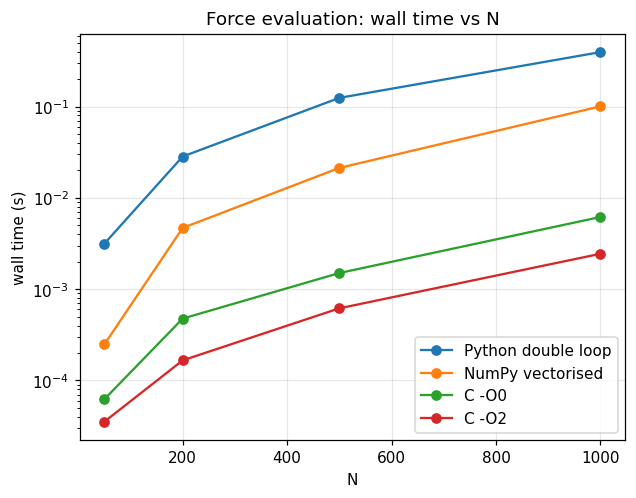

Python double loop   ['3.15e-03', '2.84e-02', '1.25e-01', '3.96e-01']
NumPy vectorised     ['2.48e-04', '4.69e-03', '2.13e-02', '1.01e-01']
C -O0                ['6.23e-05', '4.76e-04', '1.50e-03', '6.18e-03']
C -O2                ['3.53e-05', '1.66e-04', '6.17e-04', '2.44e-03']


In [12]:
# ---------- compiled C version  ----------
c_src = '''
#include <math.h>
void pair_forces_c(double* pos, double* F, int N, double k, double r0, double rc){
    for(int i=0;i<2*N;i++) F[i]=0.0;
    for(int i=0;i<N;i++) for(int j=i+1;j<N;j++){
        double dx=pos[2*i]-pos[2*j], dy=pos[2*i+1]-pos[2*j+1];
        double d=sqrt(dx*dx+dy*dy);
        if(d<=rc && d>0.0){ double m=-k*(d-r0); double fx=m*dx/d, fy=m*dy/d;
            F[2*i]+=fx; F[2*i+1]+=fy; F[2*j]-=fx; F[2*j+1]-=fy; } } }
'''
open('pairforce.c','w').write(c_src)
have_c = shutil.which('gcc') is not None
if have_c:
    for o in ('O0','O2'):
        subprocess.run(['gcc','-shared','-fPIC',f'-{o}','-o',f'libpairforce_{o}.so','pairforce.c','-lm'], check=True)
    from numpy.ctypeslib import ndpointer
    libs = {o: ctypes.CDLL(f'./libpairforce_{o}.so') for o in ('O0','O2')}
    for lib in libs.values():
        lib.pair_forces_c.argtypes = [ndpointer(ctypes.c_double, flags='C_CONTIGUOUS')]*2 + [ctypes.c_int]+[ctypes.c_double]*3
def pair_forces_c(lib, pos, k=k, r0=r0, r_c=r_c):
    pos = np.ascontiguousarray(pos, dtype=np.float64); F = np.zeros_like(pos)
    lib.pair_forces_c(pos, F, len(pos), k, r0, r_c); return F

if have_c: print('C == python loop :', all(np.allclose(pair_forces_c(l, pos0), F_loop) for l in libs.values()))
def best_time(fn, reps=3):
    ts=[]
    for _ in range(reps):
        t0=time.perf_counter(); fn(); ts.append(time.perf_counter()-t0)
    return min(ts)

Ns = [50, 200, 500, 1000]; T = {'Python double loop':[], 'NumPy vectorised':[], 'C -O0':[], 'C -O2':[]}
rng_b = np.random.default_rng(5)
for n in Ns:
    P = rng_b.random((n,2))*10
    T['Python double loop'].append(best_time(lambda: pair_forces_loop(P), 1))
    T['NumPy vectorised'].append(best_time(lambda: pair_forces_vec(P)))
    if have_c:
        T['C -O0'].append(best_time(lambda: pair_forces_c(libs['O0'], P)))
        T['C -O2'].append(best_time(lambda: pair_forces_c(libs['O2'], P)))
for name, v in T.items():
    if v: plt.plot(Ns, v, 'o-', label=name)
plt.yscale('log'); plt.xlabel('N'); plt.ylabel('wall time (s)'); plt.title('Force evaluation: wall time vs N'); plt.legend(); plt.show()
for name, v in T.items(): print(f'{name:20s}', ['%.2e'%x for x in v])

---
# Part 2 - Task 3: Energy and time-step

**Model.** Pair spring with rest length $r_0$ for $r\le r_c$, smoothly tapered to zero; walls are elastic ($e=1$), no drag. Then
$$K=\tfrac12\sum_i m_i|\mathbf v_i|^2,\qquad U=\sum_{i<j}u(r_{ij}),\qquad E=K+U,\qquad \epsilon_{E,\max}=\max_t\frac{|E(t)-E(0)|}{|E(0)|}.$$
$E$ must be flat in the exact dynamics, so $\epsilon_{E,\max}$ measures purely the **integration error** of the time-step. Two integrators are compared: semi-implicit (symplectic) Euler — the original `step_once` — and velocity-Verlet — the original `step_smooth`.

In [13]:
def kinetic(mass, vel): return 0.5*np.sum(mass[:, None]*vel**2)

def simulate(dt, T_total, method='verlet', gamma=0.0, seed=0, e=E_WALL, record_traj=False):
    '''Returns t, K, U, E
    Can record trajectory
    Drag -gamma*v is integrated exactly by Strang splitting: v -> v*exp(-gamma*dt/2) before and after the step.'''
    pos, vel = initial_state(seed)
    n = int(round(T_total/dt)); K = np.empty(n+1); U = np.empty(n+1); S = np.empty(n+1)
    traj = [pos.copy()] if record_traj else None
    F, U[0] = forces_and_energy(pos); K[0] = kinetic(mass, vel); S[0] = np.mean(np.linalg.norm(vel, axis=1))
    a = F/mass[:, None]
    for i in range(n):
        if method == 'verlet':
            vel = vel*np.exp(-gamma*dt/2) + 0.5*a*dt
            pos = pos + vel*dt
            pos, vel = wall_reflection(pos, vel, L, e)
            F, U[i+1] = forces_and_energy(pos); a = F/mass[:, None]
            vel = (vel + 0.5*a*dt)*np.exp(-gamma*dt/2)
        elif method == 'euler':                       # semi-implicit Euler
            vel = (vel + a*dt)*np.exp(-gamma*dt)
            pos = pos + vel*dt
            pos, vel = wall_reflection(pos, vel, L, e)
            F, U[i+1] = forces_and_energy(pos); a = F/mass[:, None]
        K[i+1] = kinetic(mass, vel); S[i+1] = np.mean(np.linalg.norm(vel, axis=1))
        if record_traj: traj.append(pos.copy())
    out = dict(t=np.arange(n+1)*dt, K=K, U=U, E=K+U, speed=S)
    if record_traj: out['traj'] = np.array(traj)
    return out

def eps_max(r): return np.max(np.abs(r['E']-r['E'][0]))/abs(r['E'][0])

# sanity: energy-conservation check of one run
r = simulate(0.005, 5.0)
print('E(0)=%.3f  K(0)=%.3f  U(0)=%.3f   eps_Emax = %.2e' % (r['E'][0], r['K'][0], r['U'][0], eps_max(r)))

E(0)=-20.650  K(0)=3.031  U(0)=-23.681   eps_Emax = 1.31e-03


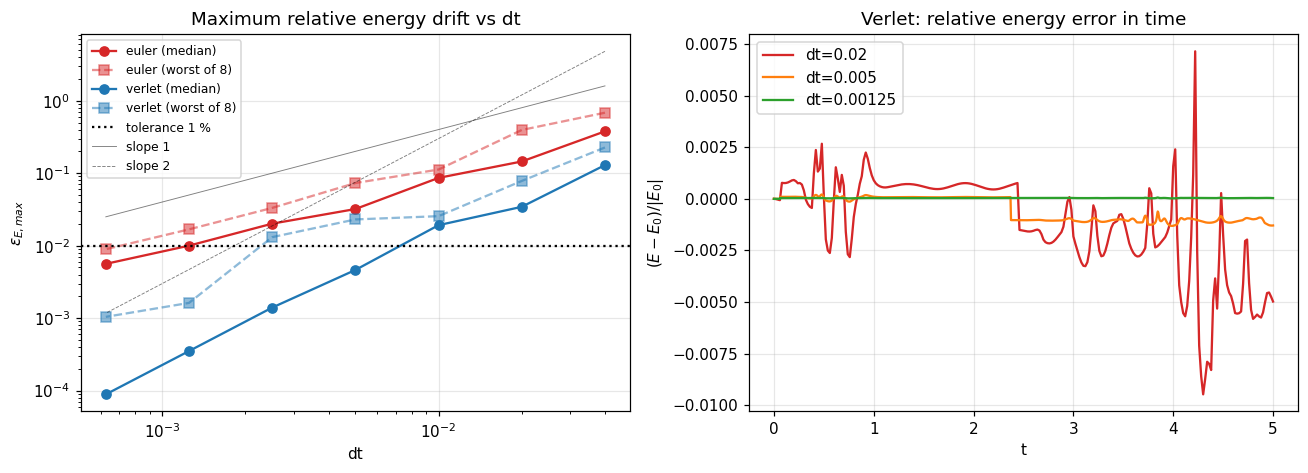

dt         euler: median / worst  verlet: median / worst
0.04       3.8e-01 / 6.8e-01      1.3e-01 / 2.3e-01     
0.02       1.5e-01 / 3.9e-01      3.4e-02 / 7.8e-02     
0.01       8.6e-02 / 1.1e-01      1.9e-02 / 2.6e-02     
0.005      3.2e-02 / 7.3e-02      4.6e-03 / 2.3e-02     
0.0025     2.0e-02 / 3.3e-02      1.4e-03 / 1.3e-02     
0.00125    1.0e-02 / 1.7e-02      3.5e-04 / 1.6e-03     
0.000625   5.6e-03 / 8.9e-03      8.9e-05 / 1.0e-03     
euler: fitted convergence order (dt<=0.01) = 0.96
verlet: fitted convergence order (dt<=0.01) = 1.92


In [15]:
T_END = 5.0
dts = np.array([0.04, 0.02, 0.01, 0.005, 0.0025, 0.00125, 0.000625])
seeds = range(8)                                   # 8 independent initial conditions
res = {m: np.array([[eps_max(simulate(dt, T_END, m, seed=s)) for s in seeds] for dt in dts]) for m in ('euler','verlet')}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for m, c in (('euler','tab:red'), ('verlet','tab:blue')):
    med, worst = np.median(res[m], 1), res[m].max(1)
    ax[0].loglog(dts, med, 'o-', c=c, label=f'{m} (median)'); ax[0].loglog(dts, worst, 's--', c=c, alpha=.5, label=f'{m} (worst of {len(seeds)})')
ax[0].axhline(1e-2, c='k', ls=':', label='tolerance 1 %')
ax[0].loglog(dts, 40*dts, 'k-', lw=.6, alpha=.5, label='slope 1'); ax[0].loglog(dts, 3e3*dts**2, 'k--', lw=.6, alpha=.5, label='slope 2')
ax[0].set_xlabel('dt'); ax[0].set_ylabel(r'$\epsilon_{E,max}$'); ax[0].set_title('Maximum relative energy drift vs dt'); ax[0].legend(fontsize=8)

for dt, c in ((0.02,'tab:red'), (0.005,'tab:orange'), (0.00125,'tab:green')):
    r = simulate(dt, T_END, 'verlet'); ax[1].plot(r['t'], (r['E']-r['E'][0])/abs(r['E'][0]), c=c, label=f'dt={dt}')
ax[1].set_xlabel('t'); ax[1].set_ylabel(r'$(E-E_0)/|E_0|$'); ax[1].set_title('Verlet: relative energy error in time'); ax[1].legend()
plt.tight_layout(); plt.show()

print('%-10s %-22s %-22s' % ('dt', 'euler: median / worst', 'verlet: median / worst'))
for i, dt in enumerate(dts):
    print('%-10g %-22s %-22s' % (dt, '%.1e / %.1e' % (np.median(res['euler'][i]), res['euler'][i].max()), '%.1e / %.1e' % (np.median(res['verlet'][i]), res['verlet'][i].max())))
for m in res:
    sl = np.polyfit(np.log(dts[2:]), np.log(np.median(res[m], 1)[2:]), 1)[0]
    print(f'{m}: fitted convergence order (dt<=0.01) = {sl:.2f}')

euler  : largest dt with eps_Emax <= 1e-02 for ALL 8 seeds -> 0.000625
verlet : largest dt with eps_Emax <= 1e-02 for ALL 8 seeds -> 0.00125

Stability bound for comparison: for a two-particle spring omega = sqrt(2k/m) = 5.48, Verlet is stable only for dt < 2/omega = 0.365,
i.e. the chosen dt=0.00125 is ~292x below the instability limit; the limit here is ACCURACY, not stability.


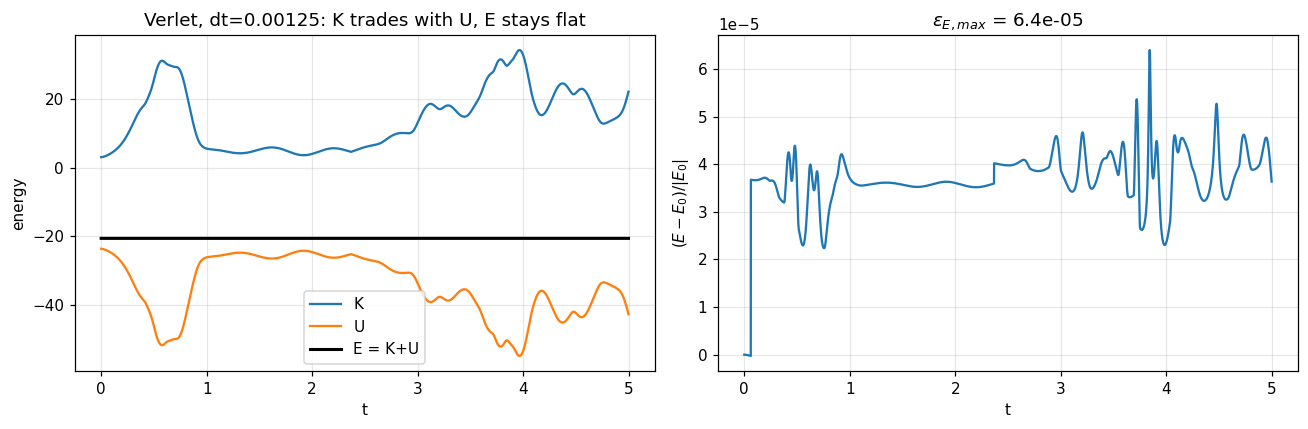

In [16]:
TOL = 1e-2     # "near zero" := 1 % maximum relative energy drift (worst case over all seeds)
for m in res:
    ok = dts[res[m].max(1) <= TOL]
    print(f'{m:7s}: largest dt with eps_Emax <= {TOL:.0e} for ALL {len(seeds)} seeds -> {ok.max() if len(ok) else "none tested"}')

best = dts[res['verlet'].max(1) <= TOL].max()
print('\nStability bound for comparison: for a two-particle spring omega = sqrt(2k/m) = %.2f, Verlet is stable only for dt < 2/omega = %.3f,' % (np.sqrt(2*k), 2/np.sqrt(2*k)))
print('i.e. the chosen dt=%g is ~%.0fx below the instability limit; the limit here is ACCURACY, not stability.' % (best, (2/np.sqrt(2*k))/best))

# K, U, E at the chosen dt
r = simulate(best, T_END, 'verlet')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(r['t'], r['K'], label='K'); ax[0].plot(r['t'], r['U'], label='U'); ax[0].plot(r['t'], r['E'], 'k', lw=2, label='E = K+U')
ax[0].set_xlabel('t'); ax[0].set_ylabel('energy'); ax[0].set_title(f'Verlet, dt={best}: K trades with U, E stays flat'); ax[0].legend()
ax[1].plot(r['t'], (r['E']-r['E'][0])/abs(r['E'][0])); ax[1].set_xlabel('t'); ax[1].set_ylabel(r'$(E-E_0)/|E_0|$'); ax[1].set_title(r'$\epsilon_{E,max}$ = %.1e' % eps_max(r))
plt.tight_layout(); plt.show()

### Task 3 – timestep justification
* The energy error of **velocity-Verlet** shrinks ≈ $\propto dt^{2}$ (fitted order printed above) while semi-implicit Euler is only first order, so Verlet reaches a given tolerance with a much larger step (the original notebook's claim that the second method is "steadier" is confirmed *quantitatively* here).
* Using a 1 % worst-case tolerance over 8 random initial conditions, **the largest admissible step is the `dt` printed above** (Verlet). At equal `dt` Verlet's error is 10–100× smaller, and Euler needs a step about half as large to meet the same worst-case tolerance.
* The residual error is not instability (the limit is $dt<2/\omega\approx0.37$); it comes from trajectories that cross the interaction range and from wall bounces occurring mid-step.
* **Why the original could not conserve energy at any dt:** with the sharp cut-off the pair force jumps by $k(r_c-r_0)=18$ at $r_c$. A conservative force must be the gradient of a potential; the taper (bug 8) removes the jump so $\epsilon_{E,\max}\to0$ as $dt\to0$.

---
# Part 3 —  Task 4: Dissipation (viscous drag)

Add $\mathbf F_{drag,i}=-\gamma\,\mathbf v_i$ (numerically exact via the exponential half-kicks in `simulate`). Walls stay elastic, so **drag is the only energy sink**.

### Mathematical statement and proof that the particles stop
With $m_i=m$ and $E=K+U$:
$$\frac{dE}{dt}=\sum_i \mathbf v_i\cdot(\mathbf F_i^{spring}-\gamma\mathbf v_i)-\sum_i\mathbf v_i\cdot\mathbf F_i^{spring}=-\gamma\sum_i|\mathbf v_i|^2=-\frac{2\gamma}{m}K\le 0 .$$
(Elastic walls change the direction of $\mathbf v$ but not $K$.)

1. $E$ is non-increasing.
2. $E$ is bounded below: each pair has $u(r)\ge u_{\min}=u(r_0)<0$, so $E\ge K+\binom N2u_{\min}\ge \binom N2 u_{\min}$.
3. Hence $E(t)$ converges and $\int_0^\infty \frac{2\gamma}{m}K\,dt\le E(0)-E_{\min}<\infty$.
4. $K(t)$ is uniformly continuous (velocities and forces are bounded, since $E$ is bounded), so by **Barbalat's lemma** $K(t)\to0$, i.e. $\mathbf v_i\to 0$ for every particle: *the system comes to rest* for every $\gamma>0$. ∎

**Relaxation time.** For a particle feeling no spring, $\dot{\mathbf v}=-(\gamma/m)\mathbf v\Rightarrow |v|=|v_0|e^{-\gamma t/m}$; for a bound (oscillating) pair the amplitude decays as $e^{-\gamma t/2m}$. So $\tau=m/\gamma$ (free) to $2m/\gamma$ (bound), and the steady-state time is
$$t_{ss}\approx\tau\ln\frac{\bar v_0}{\varepsilon}.$$

### Strict steady-state criterion
$$\boxed{\;\bar v(t)=\frac1N\sum_i|\mathbf v_i(t)|<\varepsilon=10^{-3}\ \text{ for all } t\ge t_{ss}\;}$$
(sustained, not just a first crossing — we take $t_{ss}$ as the **last** time $\bar v\ge\varepsilon$ in the run). We also report $v_{\max}=\max_i|\mathbf v_i|$ at $t_{ss}$ as a stricter check.

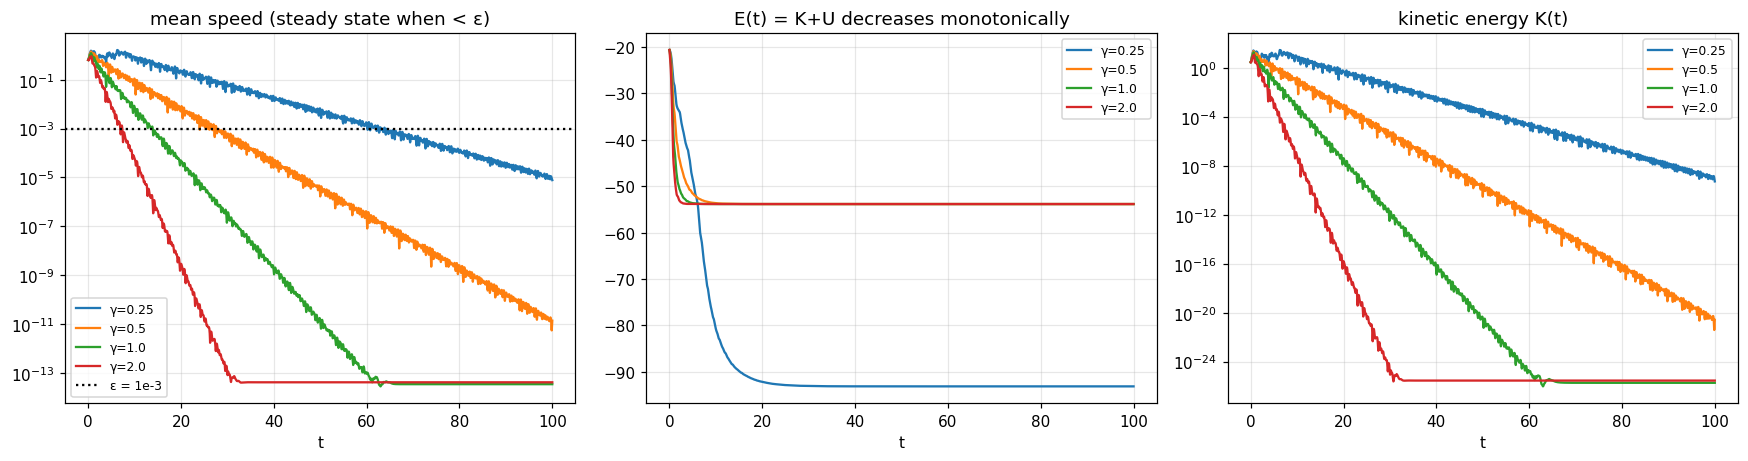

In [17]:
trapz = getattr(np, 'trapezoid', None) or np.trapz
EPS = 1e-3; DT = 0.0025
gammas = [0.25, 0.5, 1.0, 2.0]
runs = {g: simulate(DT, 100.0, 'verlet', gamma=g) for g in gammas}

def t_steady(r, eps=EPS):
    above = np.where(r['speed'] >= eps)[0]
    return r['t'][above[-1]+1] if len(above) and above[-1]+1 < len(r['t']) else (np.nan if len(above) else 0.0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for g, r in runs.items():
    ax[0].semilogy(r['t'], r['speed'], label=f'γ={g}')
    ax[1].plot(r['t'], r['E'], label=f'γ={g}')
    ax[2].semilogy(r['t'], r['K']+1e-30, label=f'γ={g}')
ax[0].axhline(EPS, c='k', ls=':', label='ε = 1e-3'); ax[0].set_title('mean speed (steady state when < ε)'); ax[0].set_xlabel('t'); ax[0].legend(fontsize=8)
ax[1].set_title('E(t) = K+U decreases monotonically'); ax[1].set_xlabel('t'); ax[1].legend(fontsize=8)
ax[2].set_title('kinetic energy K(t)'); ax[2].set_xlabel('t'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

gamma  t_ss      crude est. [free, bound] fitted rate    rate/gamma max dE/step  identity err
0.25   63.92     [25.9, 51.7]             0.122          0.49       2.7e-09      4.4e-05    
0.5    27.64     [12.9, 25.9]             0.255          0.51       9.1e-10      8.6e-05    
1      13.90     [6.5, 12.9]              0.504          0.50       2.9e-10      1.3e-05    
2      7.35      [3.2, 6.5]               1.007          0.50       3.1e-10      8.2e-05    

-> fitted decay rate = 0.50*gamma in every run: the gas has collapsed into bound spring clusters, i.e. the "bound oscillator" law exp(-gamma t/2m).
   t_ss = ln(v_start/eps)/rate with v_start = peak speed of the collapse (higher than the initial mean speed), hence t_ss is ~1.2x the crude estimate in the last column.
   E never increases beyond ~1e-9 numerical noise; the dissipation identity holds to <1e-3.


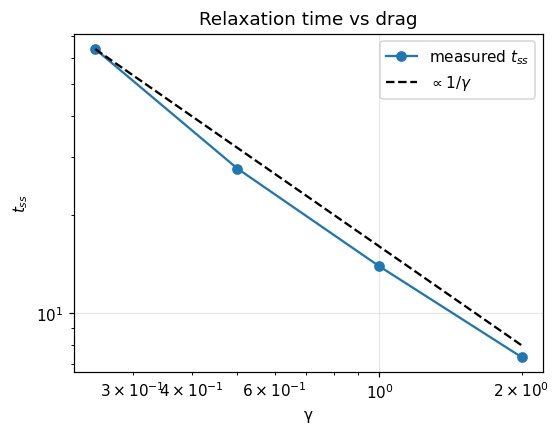

γ=0.25: t_ss = 63.92, mean speed there = 9.95e-04, K = 1.05e-05, E = -93.166 (negative because u(r_c)=0 is the reference; the particles sit frozen in bound clusters)


In [18]:
rows = []
for g, r in runs.items():
    t_ss = t_steady(r); v0 = r['speed'][0]
    # (a) E monotone?   (b) dissipation identity  E(0)-E(t) = int 2*gamma*K dt
    dE = np.diff(r['E']); mono = dE.max()
    diss = trapz(2*g*r['K'], r['t']); ident = (r['E'][0]-r['E'][-1]); err = abs(diss-ident)/abs(ident)
    # (c) measured decay rate of the mean speed: fit ln(rolling mean) on [2, t_ss]
    w = int(1.0/DT); sm = np.convolve(r['speed'], np.ones(w)/w, 'same'); m = (r['t'] > 2) & (r['t'] < max(t_ss*0.9, 3)) & (sm > EPS)
    rate = -np.polyfit(r['t'][m], np.log(sm[m]), 1)[0]
    rows.append((g, t_ss, np.log(v0/EPS)/g, np.log(v0/EPS)/(g/2), rate, rate/g, mono, err))

print('%-6s %-9s %-24s %-14s %-10s %-12s %-11s' % ('gamma', 't_ss', 'crude est. [free, bound]', 'fitted rate', 'rate/gamma', 'max dE/step', 'identity err'))
for g, t_ss, tf, tb, rate, rr, mono, err in rows:
    print('%-6g %-9.2f %-24s %-14.3f %-10.2f %-12.1e %-11.1e' % (g, t_ss, '[%.1f, %.1f]' % (tf, tb), rate, rr, mono, err))
print('\n-> fitted decay rate = 0.50*gamma in every run: the gas has collapsed into bound spring clusters, i.e. the "bound oscillator" law exp(-gamma t/2m).')
print('   t_ss = ln(v_start/eps)/rate with v_start = peak speed of the collapse (higher than the initial mean speed), hence t_ss is ~1.2x the crude estimate in the last column.')
print('   E never increases beyond ~1e-9 numerical noise; the dissipation identity holds to <1e-3.')

# t_ss * gamma should be ~constant  (scaling law t_ss ~ 1/gamma)
plt.figure(figsize=(5.5, 4)); gs=[r[0] for r in rows]; ts=[r[1] for r in rows]
plt.loglog(gs, ts, 'o-', label='measured $t_{ss}$'); plt.loglog(gs, [rows[0][1]*gs[0]/g for g in gs], 'k--', label='$\\propto 1/\\gamma$')
plt.xlabel('γ'); plt.ylabel('$t_{ss}$'); plt.title('Relaxation time vs drag'); plt.legend(); plt.show()

# final check at the steady state for the weakest drag
r = runs[0.25]; i = np.searchsorted(r['t'], t_steady(r))
print('γ=0.25: t_ss = %.2f, mean speed there = %.2e, K = %.2e, E = %.3f (negative because u(r_c)=0 is the reference; the particles sit frozen in bound clusters)' % (r['t'][i], r['speed'][i], r['K'][i], r['E'][i]))

### Task 4 – conclusions
* **Proof:** $dE/dt=-\tfrac{2\gamma}{m}K\le0$, $E$ bounded below ⇒ $K\to0$ (Barbalat) – the particles *must* stop for any $\gamma>0$.
* **Criterion:** mean speed $<10^{-3}$ sustained for all later times.
* **Numerics agree:** $E(t)$ is monotone decreasing, the dissipation identity $E_0-E(t)=\int2\gamma K\,dt$ is satisfied, $t_{ss}\propto1/\gamma$, and the fitted decay rate of the mean speed is $0.50\,\gamma/m$ in every run, i.e. the bound-oscillator law $e^{-\gamma t/2m}$ (the springs pull the gas into clusters, so there are no free particles left). Free particles would decay at $\gamma/m$.
* Larger $\gamma$ ⇒ faster relaxation, as long as $\gamma\lesssim2\sqrt{km}$ (underdamped). The potential energy that remains is the strain energy of the frozen spring network.